In [25]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import os
os.makedirs("hr-attrition-analysis/data_clean", exist_ok=True)
df.to_csv("hr-attrition-analysis/data_clean/hr_attrition_clean.csv", index=False)

In [2]:
df = pd.read_csv("/content/WA_Fn-UseC_-HR-Employee-Attrition.csv")

In [3]:
df.head()

,Age,Attrition,BusinessTravel,DailyRate,Department,DistanceFromHome,Education,EducationField,EmployeeCount,EmployeeNumber,...,RelationshipSatisfaction,StandardHours,StockOptionLevel,TotalWorkingYears,TrainingTimesLastYear,WorkLifeBalance,YearsAtCompany,YearsInCurrentRole,YearsSinceLastPromotion,YearsWithCurrManager
0,41,Yes,Travel_Rarely,1102,Sales,1,2,Life Sciences,1,1,...,1,80,0,8,0,1,6,4,0,5
1,49,No,Travel_Frequently,279,Research & Development,8,1,Life Sciences,1,2,...,4,80,1,10,3,3,10,7,1,7
2,37,Yes,Travel_Rarely,1373,Research & Development,2,2,Other,1,4,...,2,80,0,7,3,3,0,0,0,0
3,33,No,Travel_Frequently,1392,Research & Development,3,4,Life Sciences,1,5,...,3,80,0,8,3,3,8,7,3,0
4,27,No,Travel_Rarely,591,Research & Development,2,1,Medical,1,7,...,4,80,1,6,3,3,2,2,2,2


In [4]:
df.shape

(1470, 35)

In [5]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 1470 entries, 0 to 1469
Data columns (total 35 columns):
 #   Column                    Non-Null Count  Dtype 
---  ------                    --------------  ----- 
 0   Age                       1470 non-null   int64 
 1   Attrition                 1470 non-null   object
 2   BusinessTravel            1470 non-null   object
 3   DailyRate                 1470 non-null   int64 
 4   Department                1470 non-null   object
 5   DistanceFromHome          1470 non-null   int64 
 6   Education                 1470 non-null   int64 
 7   EducationField            1470 non-null   object
 8   EmployeeCount             1470 non-null   int64 
 9   EmployeeNumber            1470 non-null   int64 
 10  EnvironmentSatisfaction   1470 non-null   int64 
 11  Gender                    1470 non-null   object
 12  HourlyRate                1470 non-null   int64 
 13  JobInvolvement            1470 non-null   int64 
 14  JobLevel                

In [6]:
df['Attrition'].value_counts()

,count
Attrition,
No,1233
Yes,237


In [7]:
df[['EmployeeCount', 'StandardHours', 'Over18']].nunique()

,0
EmployeeCount,1
StandardHours,1
Over18,1


In [9]:
df = df.drop(columns=["EmployeeCount", "StandardHours", "Over18", "EmployeeNumber"])
print(df.shape)

(1470, 31)


In [10]:
df.groupby("OverTime")["Attrition"].value_counts(normalize=True)

OverTime  Attrition
No        No           0.895636
          Yes          0.104364
Yes       No           0.694712
          Yes          0.305288
Name: proportion, dtype: float64

In [11]:
df.groupby("JobRole")["Attrition"].value_counts(normalize=True).unstack()

Attrition,No,Yes
JobRole,,
Healthcare Representative,0.931298,0.068702
Human Resources,0.769231,0.230769
Laboratory Technician,0.760618,0.239382
Manager,0.950980,0.049020
Manufacturing Director,0.931034,0.068966
Research Director,0.975000,0.025000
Research Scientist,0.839041,0.160959
Sales Executive,0.825153,0.174847
Sales Representative,0.602410,0.397590


In [12]:
df["JobRole"].value_counts()

,count
JobRole,
Sales Executive,326
Research Scientist,292
Laboratory Technician,259
Manufacturing Director,145
Healthcare Representative,131
Manager,102
Sales Representative,83
Research Director,80
Human Resources,52


In [13]:
df.groupby("Attrition")["MonthlyIncome"].median()

,MonthlyIncome
Attrition,
No,5204.0
Yes,3202.0


In [14]:
df.groupby("JobLevel")["Attrition"].value_counts(normalize=True).unstack()

Attrition,No,Yes
JobLevel,,
1,0.736648,0.263352
2,0.902622,0.097378
3,0.853211,0.146789
4,0.952830,0.047170
5,0.927536,0.072464


In [15]:
df.groupby(["JobLevel", "OverTime"])["Attrition"].value_counts(normalize=True).unstack()

Attrition                No       Yes
JobLevel OverTime                    
1        No        0.842377  0.157623
         Yes       0.474359  0.525641
2        No        0.932990  0.067010
         Yes       0.821918  0.178082
3        No        0.877419  0.122581
         Yes       0.793651  0.206349
4        No        0.972603  0.027397
         Yes       0.909091  0.090909
5        No        0.960784  0.039216
         Yes       0.833333  0.166667

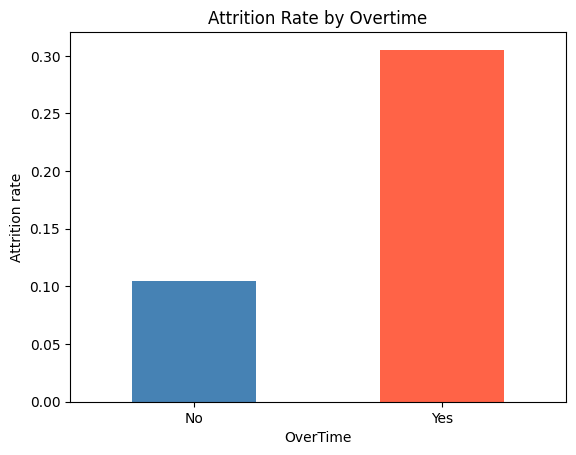

In [18]:
rates = df.groupby("OverTime")["Attrition"].apply(lambda x: (x == "Yes").mean())
rates.plot(kind="bar", color=["steelblue", "tomato"])
plt.title("Attrition Rate by Overtime")
plt.ylabel("Attrition rate")
plt.xticks(rotation=0)
plt.show()

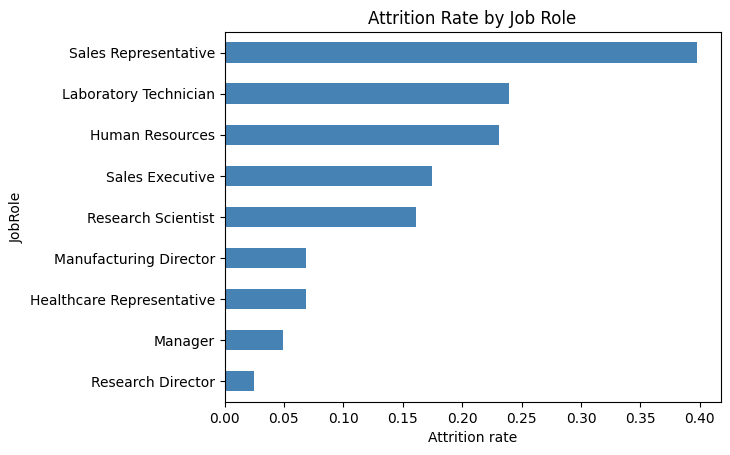

In [19]:
role_rates = df.groupby("JobRole")["Attrition"].apply(lambda x: (x == "Yes").mean()).sort_values()
role_rates.plot(kind="barh", color="steelblue")
plt.title("Attrition Rate by Job Role")
plt.xlabel("Attrition rate")
plt.show()

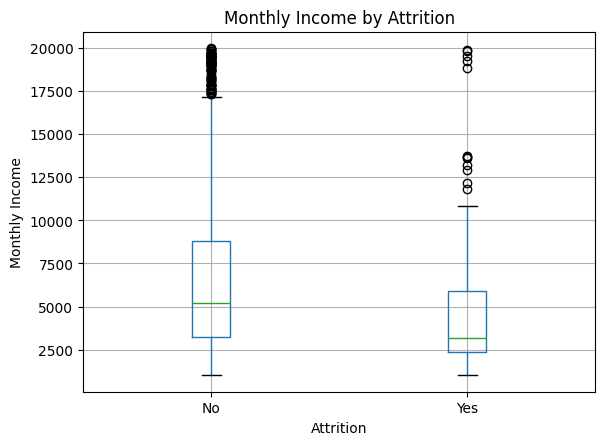

In [21]:
df.boxplot(column="MonthlyIncome", by="Attrition")
plt.title("Monthly Income by Attrition")
plt.suptitle("")
plt.ylabel("Monthly Income")
plt.show()

In [22]:
df["AttritionFlag"] = (df["Attrition"] == "Yes").astype(int)
df.corr(numeric_only=True)["AttritionFlag"].sort_values()

,AttritionFlag
TotalWorkingYears,-0.171063
JobLevel,-0.169105
YearsInCurrentRole,-0.160545
MonthlyIncome,-0.159840
Age,-0.159205
YearsWithCurrManager,-0.156199
StockOptionLevel,-0.137145
YearsAtCompany,-0.134392
JobInvolvement,-0.130016
JobSatisfaction,-0.103481


In [23]:
df.groupby("BusinessTravel")["Attrition"].value_counts(normalize=True).unstack()

Attrition,No,Yes
BusinessTravel,,
Non-Travel,0.920000,0.080000
Travel_Frequently,0.750903,0.249097
Travel_Rarely,0.850431,0.149569


In [24]:
df["BusinessTravel"].value_counts()

,count
BusinessTravel,
Travel_Rarely,1043
Travel_Frequently,277
Non-Travel,150
